# Step 5 — 2D Linear Convection

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step05_linear_convection_2d.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

We now move from 1D to 2D. The governing PDE is the 2D linear advection equation, in which a scalar field is carried by a constant velocity and keeps its shape.

**What you will learn:**

1. How sesmax represents 2D fields on a regular grid
2. The Arakawa C-grid staggering convention
3. How to run a 2D simulation and visualize the result
4. How to differentiate through the 2D solver

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial u}{\partial t} + c_x \frac{\partial u}{\partial x} + c_y \frac{\partial u}{\partial y} = 0
$$

where $(c_x, c_y)$ is the constant advection velocity. The initial profile translates with that velocity without distortion, so this is pure **advection**.

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ and $y$ are the spatial coordinates (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$, $y \in [0, L_y)$ | spatial coordinates | $\mathbb{R}$ |
| $t \in [t_0, t_1]$ | time | $\mathbb{R}$ |
| $u(x, y, t)$ | the advected field | $\mathbb{R}$ |
| $u_0(x, y)$ | initial condition, a Gaussian bump with centre $(\mu_x, \mu_y)$ and width $\sigma_0$ | $\mathbb{R}$ |
| $c_x$, $c_y$ | advection velocity components, the model's differentiable parameters | $\mathbb{R}$ |
| $L_x$, $L_y$ | domain lengths | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior grid cells along $x$ and $y$ | count |
| $\Delta x = L_x / N_{\Omega_x,x}$, $\Delta y = L_y / N_{\Omega_x,y}$, $\Delta t$ | grid spacings and time step | $\mathbb{R}_{>0}$ |
| $u_{j,i}$ | the field in the cell at row $j$ and column $i$; the array has $N_{\Omega_x,y} + 2$ rows and $N_{\Omega_x,x} + 2$ columns with the ghosts | $\mathbb{R}$ |
| $M(t)$ | total mass | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |

## Grid layout and boundary conditions

The field $u$ lives at the T-points of [](#fig-cgrid-positions), in an array with a one-cell ghost ring around the $N_{\Omega_x,y} \times N_{\Omega_x,x}$ interior cells, so the interior is `[1:-1, 1:-1]`. Periodic boundaries {eq}`cgrid-periodic` fill the ring from the opposite edges before each evaluation of the right-hand side. Later steps stagger their velocities as well, for the reason {eq}`cgrid-momentum` gives.

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.1.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model and grid

`LinearConvection2D.create()` builds a model on a 2D Arakawa C-grid with `nx` by `ny` interior cells spanning a domain of size `Lx` by `Ly`. The velocity components `cx` and `cy` are differentiable parameters visible to `jax.grad`.

In [4]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells

num_cells_x = 64
num_cells_y = 64
domain_length_x = 2.0
domain_length_y = 2.0
velocity_x = 1.0
velocity_y = 0.5

# today (sesmax_core)
model = sxt.LinearConvection2D.create(
    nx=num_cells_x,
    ny=num_cells_y,
    Lx=domain_length_x,
    Ly=domain_length_y,
    cx=velocity_x,
    cy=velocity_y,
)

print(model)
print(f"Grid: Nx={model.grid.Nx}, Ny={model.grid.Ny}")
print(f"Spacing: dx={model.grid.spacing('x'):.4f}, dy={model.grid.spacing('y'):.4f}")

LinearConvection2D(
  params=LinearConvection2DParams(cx=weak_f32[], cy=weak_f32[]),
  grid=CartesianCGrid2D(Nx=66, Ny=66, Lx=f64[](numpy), Ly=f64[](numpy)),
  diff=Difference2D(
    grid=CartesianCGrid2D(Nx=66, Ny=66, Lx=f64[](numpy), Ly=f64[](numpy))
  ),
  interp=Interpolation2D(
    grid=CartesianCGrid2D(Nx=66, Ny=66, Lx=f64[](numpy), Ly=f64[](numpy))
  ),
  mask=None
)
Grid: Nx=66, Ny=66
Spacing: dx=0.0312, dy=0.0312


## 2. Initial condition

A 2D Gaussian bump centred at $(\mu_x, \mu_y) = (1, 1)$ with width $\sigma_0 = 0.2$:

$$
u_0(x, y) = \exp\left(-\frac{(x - \mu_x)^2 + (y - \mu_y)^2}{2 \sigma_0^2}\right)
$$

In [5]:
# Shapes: N_Ωx,x + 2 = 66 columns and N_Ωx,y + 2 = 66 rows with the ghosts;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

centre_x = 1.0
centre_y = 1.0
bump_width = 0.2
inner = slice(1, -1)
interior = (inner, inner)

# xᵢ = i Δx
x_position = jnp.arange(model.grid.Nx) * model.grid.spacing("x")  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_position = jnp.arange(model.grid.Ny) * model.grid.spacing("y")  # → (N_Ωx,y + 2,)
# (xᵢ, yⱼ) on every cell
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# zₓ = (x − μₓ) / σ₀
standardised_x = (x_grid - centre_x) / bump_width  # → G
# z_y = (y − μ_y) / σ₀
standardised_y = (y_grid - centre_y) / bump_width  # → G
# u₀(x, y) = exp(−(zₓ² + z_y²) / 2)
radius_squared = standardised_x**2 + standardised_y**2  # → G
initial_u = jnp.exp(-0.5 * radius_squared)  # → G

# today (sesmax_core)
initial_state = sxt.LinearConvection2DState(u=initial_u)

print(f"State shape: u={initial_state.u.shape}")

State shape: u=(66, 66)


## 3. Run the simulation

We integrate from $t_0 = 0$ to $t_1 = 0.5$ and save a snapshot every time step.

In [6]:
# Shapes: N_T = 250 saved snapshots; N_Ωx,y + 2 = 66 rows and N_Ωx,x + 2 = 66 columns;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

time_step = 0.002
start_time = 0.0
end_time = 0.5

# tₖ = t₀ + k Δt
save_times = jnp.arange(start_time, end_time, time_step)  # → (N_T,)

# today (sesmax_core, diffrax)
# u(x, y, tₖ) for each saved time
solution = model.integrate(  # u → N_T × G
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

print(f"Solution shape: {solution.ys.u.shape}")

Solution shape: (250, 66, 66)


## 4. Visualize initial and final fields

We plot only the interior cells (excluding ghost cells) using `pcolormesh`.

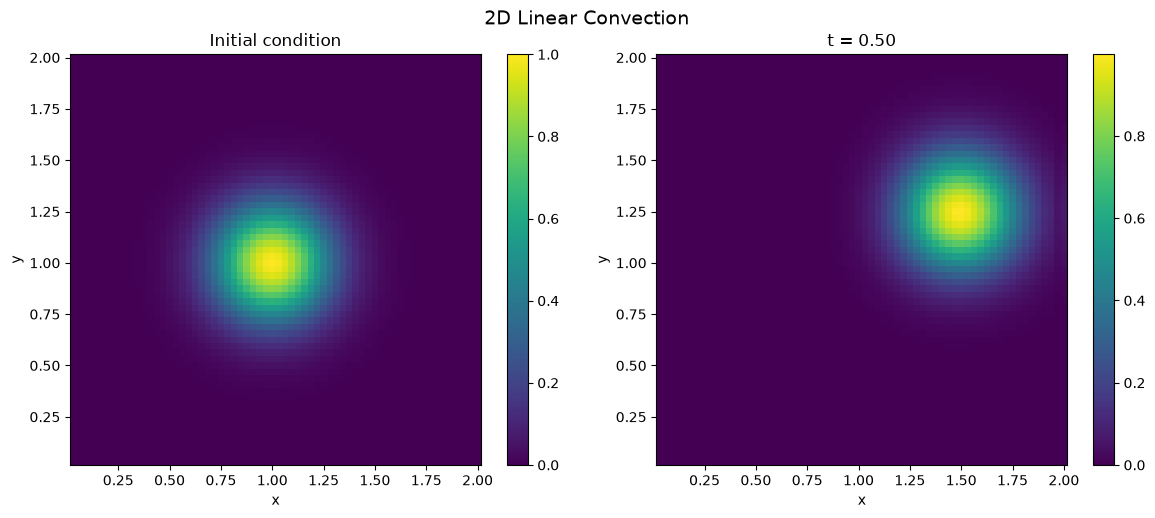

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, field, title in zip(
    axes,
    [solution.ys.u[0], solution.ys.u[-1]],
    ["Initial condition", f"t = {float(save_times[-1]):.2f}"],
    strict=True,
):
    pcm = ax.pcolormesh(
        x_grid[interior],
        y_grid[interior],
        field[interior],
        shading="auto",
        cmap="viridis",
    )
    plt.colorbar(pcm, ax=ax)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)
    ax.set_aspect("equal")

plt.suptitle("2D Linear Convection", fontsize=14)
plt.tight_layout()
plt.show()

The Gaussian translates in the $(c_x, c_y) = (1.0, 0.5)$ direction without changing shape — exactly what the linear advection equation predicts.

## 5. Cross-section through the centre

A 1D slice along the mid-$y$ row shows the translation more clearly.

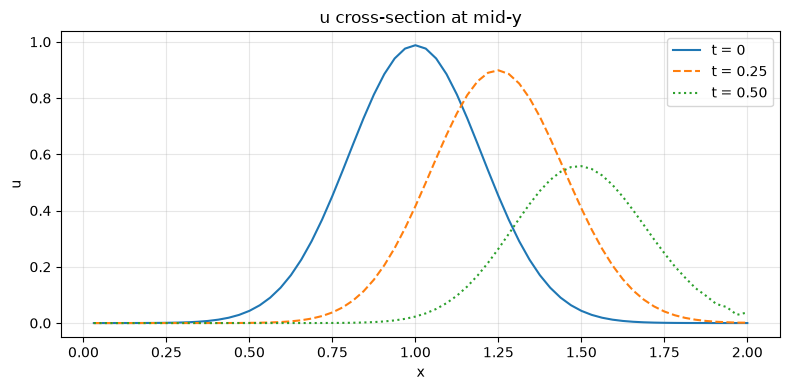

In [8]:
# Shapes: N_T = 250 saved snapshots; N_Ωx,y + 2 = 66 rows and N_Ωx,x + 2 = 66 columns

mid_row = model.grid.Ny // 2
mid_snapshot = len(save_times) // 2

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_position[inner], solution.ys.u[0, mid_row, inner], label="t = 0", lw=1.5)
ax.plot(
    x_position[inner],
    solution.ys.u[mid_snapshot, mid_row, inner],
    label=f"t = {float(save_times[mid_snapshot]):.2f}",
    lw=1.5,
    ls="--",
)
ax.plot(
    x_position[inner],
    solution.ys.u[-1, mid_row, inner],
    label=f"t = {float(save_times[-1]):.2f}",
    lw=1.5,
    ls=":",
)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title("u cross-section at mid-y")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The pulse shifts to the right at speed $c_x = 1.0$ with an unchanged shape. The amplitude along this slice falls because the pulse also moves in $y$ at speed $c_y = 0.5$, away from the mid-$y$ row.

## 6. Mass conservation check

Linear advection conserves the total mass,

$$
M(t) = \int_0^{L_y} \int_0^{L_x} u(x, y, t) \mathrm{d}x \mathrm{d}y \approx \Delta x \Delta y \sum_{j=1}^{N_{\Omega_x,y}} \sum_{i=1}^{N_{\Omega_x,x}} u_{j,i}(t)
$$

We verify this by tracking the sum over time.

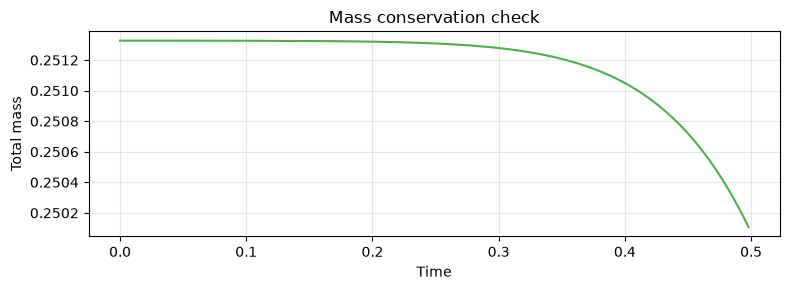

Mass: initial = 0.251327, final = 0.250106
Relative change: 4.86e-03


In [9]:
# Shapes: N_T = 250 saved snapshots; N_Ωx,y = 64 rows and N_Ωx,x = 64 columns interior

x_spacing = float(model.grid.spacing("x"))
y_spacing = float(model.grid.spacing("y"))
cell_area = x_spacing * y_spacing

# Σⱼ Σᵢ uⱼ,ᵢ(tₖ)
interior_u = solution.ys.u[:, *interior]  # → N_T × N_Ωx,y × N_Ωx,x
total_u = einx.sum("t [y x] -> t", interior_u)  # → (N_T,)
# M(tₖ) = Δx Δy Σⱼ Σᵢ uⱼ,ᵢ(tₖ)
mass = total_u * cell_area  # → (N_T,)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(save_times, mass, lw=1.5, color="#4CAF50")
ax.set_xlabel("Time")
ax.set_ylabel("Total mass")
ax.set_title("Mass conservation check")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mass: initial = {float(mass[0]):.6f}, final = {float(mass[-1]):.6f}")
print(f"Relative change: {abs(float((mass[-1] - mass[0]) / mass[0])):.2e}")

## 7. Gradients through the solver

Because sesmax models are equinox modules, we can differentiate the solution with respect to the advection velocity $(c_x, c_y)$ and the initial field at once. The second is the building block for data assimilation (4D-Var) in 2D. The loss is the sum of squares of the field at $t_1 = 0.2$ over every cell, including the ghosts,

$$
\mathcal{L}(c_x, c_y, u_0) = \sum_{j=0}^{N_{\Omega_x,y} + 1} \sum_{i=0}^{N_{\Omega_x,x} + 1} u_{j,i}(t_1; c_x, c_y, u_0)^2
$$


dL/d(cx) = -0.000010
dL/d(cy) = -0.000003


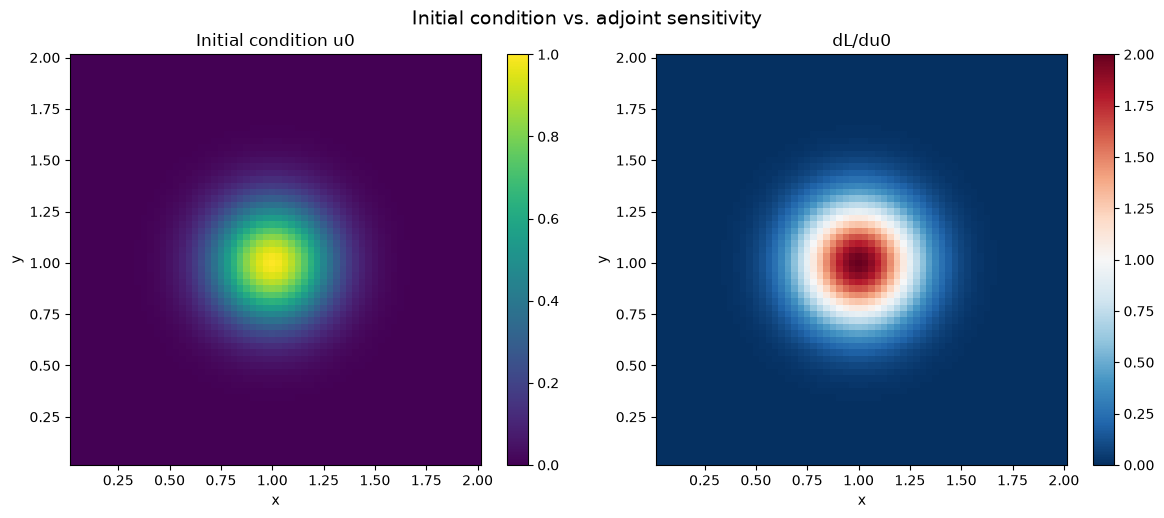

In [10]:
# Shapes: N_Ωx,y + 2 = 66 rows and N_Ωx,x + 2 = 66 columns with the ghosts;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts


def joint_loss(pair):
    """ℒ(cₓ, c_y, u₀) for a (state, model) pair."""
    state, model = pair
    # today (sesmax_core, diffrax)
    # u(x, y, t₁; cₓ, c_y, u₀)
    final_solution = model.integrate(state, t0=0.0, t1=0.2, dt=0.002)
    # ℒ = Σⱼ Σᵢ uⱼ,ᵢ(t₁)²
    return jnp.sum(final_solution.ys.u**2)  # → ()


# filter_grad differentiates only the floating-point leaves: the grid's
# integer sizes are leaves too, and jax.grad would refuse them.
# today (equinox)
# (∂ℒ/∂u₀, (∂ℒ/∂cₓ, ∂ℒ/∂c_y))
state_grads, model_grads = eqx.filter_grad(joint_loss)((initial_state, model))

print(f"dL/d(cx) = {model_grads.params.cx:.6f}")
print(f"dL/d(cy) = {model_grads.params.cy:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pcm0 = axes[0].pcolormesh(
    x_grid[interior],
    y_grid[interior],
    initial_state.u[interior],
    shading="auto",
    cmap="viridis",
)
plt.colorbar(pcm0, ax=axes[0])
axes[0].set_title("Initial condition u0")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_aspect("equal")

pcm1 = axes[1].pcolormesh(
    x_grid[interior],
    y_grid[interior],
    state_grads.u[interior],
    shading="auto",
    cmap="RdBu_r",
)
plt.colorbar(pcm1, ax=axes[1])
axes[1].set_title("dL/du0")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_aspect("equal")

plt.suptitle("Initial condition vs. adjoint sensitivity", fontsize=14)
plt.tight_layout()
plt.show()

## Summary

| Concept | API |
| --- | --- |
| Create 2D model | `LinearConvection2D.create(nx=64, ...)` |
| Grid coordinates | `jnp.arange(grid.Nx) * grid.spacing("x")` |
| Initial state | `LinearConvection2DState(u=initial_u)` with `initial_u.shape == (Ny, Nx)` |
| Joint gradient, parameters and state | `eqx.filter_grad(loss)((initial_state, model))` |

**Next:** Step 6 extends to nonlinear convection in 2D, where the velocity is no longer constant but depends on the solution itself.